# Analisis Pertumbuhan dan Location Quotient (LQ) Surabaya, 2021–2025

## 1. Pendahuluan dan tujuan analisis

**Tujuan.** Notebook ini menyajikan hasil analisis pertumbuhan kegiatan usaha dan konsentrasi sektoral (LQ) Kota Surabaya secara terstruktur sebagai bahan awal penyusunan jurnal.

**Ruang lingkup.** Periode 2021–2025; sektor menggunakan KBLI 2 digit dan wilayah menggunakan kecamatan. Notebook ini menggunakan dataset hasil cleaning dan berkas hasil analisis yang sudah tersedia. Cleaning, perhitungan LQ, dan indikator pertumbuhan yang sudah dihitung tidak diulang; agregasi tambahan untuk tabel distribusi dihitung dari kolom yang diperlukan pada dataset cleaning.

**Unit hitung.** Jumlah kegiatan adalah `Id Proyek` unik di dalam kelompok analisis yang bersangkutan. Satu ID yang tercatat pada lebih dari satu kecamatan dapat terhitung pada masing-masing kecamatan, sehingga jumlah hasil agregasi wilayah-sektor tidak selalu sama dengan jumlah ID unik kota.


## Metode dan cara membaca hasil

- **Location Quotient (LQ):** `(jumlah sektor di kecamatan / seluruh kegiatan kecamatan) / (jumlah sektor di kota / seluruh kegiatan kota)`. LQ > 1 menunjukkan konsentrasi relatif lebih tinggi daripada kota; LQ < 1 lebih rendah. LQ bukan ukuran nilai investasi, output, atau skala ekonomi.
- **Pertumbuhan tahunan (YoY):** perubahan jumlah kegiatan terhadap tahun sebelumnya. YoY 2021 tidak dihitung karena data 2020 tidak termasuk.
- **CAGR 2021–2025:** `((jumlah 2025 / jumlah 2021) ** (1/4) - 1) * 100%`, seperti pada hasil yang tersedia. CAGR merangkum dua titik endpoint, bukan lintasan tiap tahun; persentase juga peka terhadap jumlah awal yang kecil.
- **Klasifikasi gabungan:** rata-rata LQ tahunan per sektor selama 2021–2025 dan CAGR sektor; klasifikasi hanya diberikan jika data LQ tersedia untuk kelima tahun dan CAGR dapat dihitung. Ambang basis adalah LQ > 1; ambang tumbuh adalah CAGR > 0%.

Hasil bersifat deskriptif dan tidak menguji sebab-akibat atau autokorelasi spasial. Nama KBLI representatif yang tersedia pada berkas hasil merupakan judul KBLI 5 digit terbanyak di sektor, bukan label resmi sektor 2 digit.


In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import IFrame, Image, display
from PIL import Image as PillowImage

cwd = Path.cwd().resolve()
project_dir = next(
    (candidate for candidate in (cwd, cwd.parent) if (candidate / "output").is_dir()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Folder output tidak ditemukan dari lokasi notebook saat ini.")

output_dir = project_dir / "output"
analysis_files = {
    "annual": "pertumbuhan_kegiatan_usaha_tahunan.csv",
    "sector_yoy": "pertumbuhan_kegiatan_usaha_sektor_yoy.csv",
    "district_yoy": "pertumbuhan_kegiatan_usaha_wilayah_yoy.csv",
    "growth_comparison": "perbandingan_pertumbuhan_sektor_wilayah.csv",
    "lq": "hasil_lq_kecamatan_kbli.csv",
    "lq_categories": "ringkasan_kategori_lq.csv",
    "combined": "analisis_gabungan_lq_pertumbuhan_sektor.csv",
    "combined_categories": "ringkasan_kategori_gabungan_lq_pertumbuhan.csv",
}
missing_files = [name for name in analysis_files.values() if not (output_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Berkas hasil analisis tidak ditemukan: {missing_files}")

annual = pd.read_csv(output_dir / analysis_files["annual"])
sector_yoy = pd.read_csv(output_dir / analysis_files["sector_yoy"], dtype={"KBLI_2digit": "string"})
district_yoy = pd.read_csv(output_dir / analysis_files["district_yoy"])
growth_comparison = pd.read_csv(
    output_dir / analysis_files["growth_comparison"],
    dtype={"nama_entitas": "string"},
)
lq = pd.read_csv(output_dir / analysis_files["lq"], dtype={"KBLI_2digit": "string"})
lq_categories = pd.read_csv(output_dir / analysis_files["lq_categories"])
combined = pd.read_csv(output_dir / analysis_files["combined"], dtype={"KBLI_2digit": "string"})
combined_categories = pd.read_csv(output_dir / analysis_files["combined_categories"])

years = [2021, 2022, 2023, 2024, 2025]
annual["Tahun"] = pd.to_numeric(annual["Tahun"], errors="raise").astype(int)
sector_yoy["Tahun"] = pd.to_numeric(sector_yoy["Tahun"], errors="raise").astype(int)
district_yoy["Tahun"] = pd.to_numeric(district_yoy["Tahun"], errors="raise").astype(int)
lq["Tahun"] = pd.to_numeric(lq["Tahun"], errors="raise").astype(int)
lq_categories["Tahun"] = pd.to_numeric(lq_categories["Tahun"], errors="raise").astype(int)
for frame in (sector_yoy, lq, combined):
    frame["KBLI_2digit"] = frame["KBLI_2digit"].astype("string").str.strip().str.zfill(2)

required_map_files = [
    output_dir / "peta_choropleth_lq_surabaya.html",
    output_dir / "peta_choropleth_pertumbuhan_kecamatan.html",
]
missing_maps = [path.name for path in required_map_files if not path.is_file()]
if missing_maps:
    raise FileNotFoundError(f"Berkas peta interaktif tidak ditemukan: {missing_maps}")

map_validation = []
for map_name, map_path in zip(("LQ", "Pertumbuhan"), required_map_files):
    html = map_path.read_text(encoding="utf-8")
    feature_count = len(re.findall(r'"K"\s*:\s*"', html))
    has_osm = "tile.openstreetmap.org" in html
    has_interactive_filter = (
        "lq-filter-" in html and "sectorLabels" in html
        if map_name == "LQ"
        else "growth-filter-" in html and "applyYear" in html
    )
    if not has_osm or feature_count != 31 or not has_interactive_filter:
        raise ValueError(
            f"Validasi peta {map_name} gagal: OSM={has_osm}, "
            f"jumlah kecamatan={feature_count}, filter interaktif={has_interactive_filter}"
        )
    map_validation.append(
        {"Peta": map_name, "OpenStreetMap": has_osm, "Batas kecamatan": feature_count, "Filter": has_interactive_filter}
    )
map_validation = pd.DataFrame(map_validation)


## Pemeriksaan kelengkapan dan konsistensi berkas

Pemeriksaan berikut memastikan periode, ukuran panel, cakupan kecamatan, jumlah sektor, dan kategori sesuai dengan hasil yang sudah tersimpan. Perhitungan indikator tidak diulang.


In [2]:
assert annual["Tahun"].tolist() == years
assert len(sector_yoy) == 83 * len(years)
assert len(district_yoy) == 31 * len(years)
assert len(lq) == 10_280
assert lq["kecamatan_usaha"].nunique() == 31
assert lq["Tahun"].nunique() == 5
assert lq["LQ"].notna().all()
assert not lq.duplicated(["kecamatan_usaha", "KBLI_2digit", "Tahun"]).any()
assert len(combined) == 83
assert combined["KBLI_2digit"].is_unique
assert int(combined_categories["jumlah_sektor"].sum()) == len(combined)
assert combined["kategori_gabungan"].value_counts().to_dict() == {
    "Sektor Basis dan Tumbuh": 58,
    "Sektor Non-Basis tetapi Tumbuh": 18,
    "Sektor Basis tetapi Tidak Tumbuh": 4,
    "Data tidak memadai": 3,
}
lq_aggregate_2024 = int(lq.loc[lq["Tahun"].eq(2024), "jumlah_kegiatan_usaha"].sum())
city_unique_2024 = int(annual.loc[annual["Tahun"].eq(2024), "jumlah_kegiatan_usaha"].iloc[0])
assert lq_aggregate_2024 - city_unique_2024 == 1

validation = pd.DataFrame(
    [
        ("Periode tahunan", ", ".join(map(str, annual["Tahun"].tolist())), "2021–2025"),
        ("Panel pertumbuhan sektor", f"{len(sector_yoy)} baris; 83 KBLI × 5 tahun", "415 baris"),
        ("Panel pertumbuhan kecamatan", f"{len(district_yoy)} baris; 31 kecamatan × 5 tahun", "155 baris"),
        ("Hasil LQ", f"{len(lq):,} baris; 31 kecamatan; 5 tahun; tanpa nilai kosong", "Lengkap"),
        ("Agregat 2024", f"LQ kecamatan–sektor {lq_aggregate_2024:,}; kota unik {city_unique_2024:,}; selisih +1", "Satu ID teratribusi ke 2 kecamatan"),
        ("Analisis gabungan", f"{len(combined)} sektor; kategori berjumlah {int(combined_categories['jumlah_sektor'].sum())}", "83 sektor"),
        ("Peta interaktif", f"{len(required_map_files)} berkas HTML tersedia", "2 peta"),
    ],
    columns=["Pemeriksaan", "Hasil", "Ekspektasi"],
)
display(validation)
display(map_validation)


,Pemeriksaan,Hasil,Ekspektasi
0,Periode tahunan,"2021, 2022, 2023, 2024, 2025",2021–2025
1,Panel pertumbuhan sektor,415 baris; 83 KBLI × 5 tahun,415 baris
2,Panel pertumbuhan kecamatan,155 baris; 31 kecamatan × 5 tahun,155 baris
3,Hasil LQ,"10,280 baris; 31 kecamatan; 5 tahun; tanpa nil...",Lengkap
4,Agregat 2024,"LQ kecamatan–sektor 137,450; kota unik 137,449...",Satu ID teratribusi ke 2 kecamatan
5,Analisis gabungan,83 sektor; kategori berjumlah 83,83 sektor
6,Peta interaktif,2 berkas HTML tersedia,2 peta


,Peta,OpenStreetMap,Batas kecamatan,Filter
0,LQ,True,31,True
1,Pertumbuhan,True,31,True


## 2. Memuat dataset hasil cleaning dan gambaran umum kegiatan usaha

Dataset cleaning dimuat hanya pada empat kolom analisis yang diperlukan. Perhitungan jumlah menggunakan `Id Proyek` unik untuk setiap KBLI-tahun dan kecamatan-tahun, lalu menjumlahkan lima total tahunan. Tidak ada tahap cleaning ulang. Berkas distribusi yang telah tersimpan dipakai sebagai pembanding agar agregasi dapat diverifikasi.


In [3]:
cleaned_path = output_dir / "data_clean.csv"
if not cleaned_path.is_file():
    raise FileNotFoundError(f"Dataset hasil cleaning tidak ditemukan: {cleaned_path}")

cleaned = pd.read_csv(
    cleaned_path,
    usecols=["Id Proyek", "KBLI_2digit", "kecamatan_usaha", "Tahun"],
    dtype={
        "Id Proyek": "string",
        "KBLI_2digit": "string",
        "kecamatan_usaha": "string",
    },
)
cleaned["Tahun"] = pd.to_numeric(cleaned["Tahun"], errors="raise").astype(int)
cleaned["KBLI_2digit"] = cleaned["KBLI_2digit"].str.strip().str.zfill(2)
cleaned = cleaned.loc[cleaned["Tahun"].isin(years)].copy()

sector_distribution = pd.read_csv(
    output_dir / "distribusi_kegiatan_usaha_sektor.csv",
    dtype={"KBLI_2digit": "string"},
)
district_distribution = pd.read_csv(output_dir / "distribusi_kegiatan_usaha_kecamatan.csv")
sector_distribution["KBLI_2digit"] = sector_distribution["KBLI_2digit"].str.strip().str.zfill(2)

sector_year_counts = (
    cleaned.dropna(subset=["Id Proyek", "KBLI_2digit"])
    .groupby(["KBLI_2digit", "Tahun"])["Id Proyek"]
    .nunique()
    .unstack("Tahun")
    .reindex(index=sector_distribution["KBLI_2digit"], columns=years, fill_value=0)
    .fillna(0)
    .astype(int)
)
district_year_counts = (
    cleaned.dropna(subset=["Id Proyek", "kecamatan_usaha"])
    .groupby(["kecamatan_usaha", "Tahun"])["Id Proyek"]
    .nunique()
    .unstack("Tahun")
    .reindex(index=district_distribution["kecamatan_usaha"], columns=years, fill_value=0)
    .fillna(0)
    .astype(int)
)

saved_sector = sector_distribution.set_index("KBLI_2digit").reindex(sector_year_counts.index)
saved_district = district_distribution.set_index("kecamatan_usaha").reindex(district_year_counts.index)
for year in years:
    np.testing.assert_array_equal(
        sector_year_counts[year].to_numpy(),
        pd.to_numeric(saved_sector[str(year)], errors="raise").astype(int).to_numpy(),
    )
    np.testing.assert_array_equal(
        district_year_counts[year].to_numpy(),
        pd.to_numeric(saved_district[str(year)], errors="raise").astype(int).to_numpy(),
    )

sector_period = sector_year_counts.sum(axis=1).rename("Jumlah kegiatan 2021–2025").reset_index()
sector_period = sector_period.merge(
    sector_distribution[["KBLI_2digit", "Judul_KBLI_5_digit_terbanyak"]],
    on="KBLI_2digit",
    how="left",
    validate="one_to_one",
)
district_period = district_year_counts.sum(axis=1).rename("Jumlah kegiatan 2021–2025").reset_index()

project_kbli_counts = (
    cleaned.dropna(subset=["Id Proyek", "KBLI_2digit"])
    .groupby(["Tahun", "Id Proyek"])["KBLI_2digit"]
    .nunique()
)
multi_kbli_project_years = int(project_kbli_counts.gt(1).sum())
print(f"Baris dataset cleaning yang digunakan: {len(cleaned):,}")
print(f"Pasangan Id Proyek–tahun dengan lebih dari satu KBLI: {multi_kbli_project_years}")
print("Validasi jumlah tahunan per KBLI dan kecamatan cocok dengan berkas distribusi tersimpan.")

sector_top = sector_period.nlargest(5, "Jumlah kegiatan 2021–2025").copy()
sector_top["Peringkat"] = sector_top["Jumlah kegiatan 2021–2025"].rank(
    method="min", ascending=False
).astype(int)
sector_bottom_ordered = sector_period.sort_values(
    ["Jumlah kegiatan 2021–2025", "KBLI_2digit"], ascending=[True, True]
)
sector_bottom_cutoff = sector_bottom_ordered.iloc[4]["Jumlah kegiatan 2021–2025"]
sector_bottom = sector_bottom_ordered.loc[
    sector_bottom_ordered["Jumlah kegiatan 2021–2025"].le(sector_bottom_cutoff)
].copy()
sector_bottom["Peringkat"] = sector_bottom["Jumlah kegiatan 2021–2025"].rank(
    method="min", ascending=True
).astype(int)

def display_sector_ranking(frame):
    table = frame[[
        "Peringkat", "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak", "Jumlah kegiatan 2021–2025"
    ]].rename(columns={
        "KBLI_2digit": "KBLI 2 digit",
        "Judul_KBLI_5_digit_terbanyak": "Judul KBLI representatif",
    })
    display(
        table.style
        .set_properties(
            subset=["Judul KBLI representatif"],
            **{"white-space": "normal", "max-width": "430px"},
        )
        .format({"Jumlah kegiatan 2021–2025": "{:,.0f}"})
    )

print("Tabel 1. Lima KBLI dengan jumlah kegiatan tertinggi")
display_sector_ranking(sector_top)
print("Tabel 2. Lima KBLI dengan jumlah kegiatan terendah (ikatan pada batas peringkat ditampilkan)")
display_sector_ranking(sector_bottom)

district_top = district_period.nlargest(5, "Jumlah kegiatan 2021–2025").copy()
district_top["Peringkat"] = district_top["Jumlah kegiatan 2021–2025"].rank(
    method="min", ascending=False
).astype(int)
district_bottom_ordered = district_period.sort_values(
    ["Jumlah kegiatan 2021–2025", "kecamatan_usaha"], ascending=[True, True]
)
district_bottom_cutoff = district_bottom_ordered.iloc[4]["Jumlah kegiatan 2021–2025"]
district_bottom = district_bottom_ordered.loc[
    district_bottom_ordered["Jumlah kegiatan 2021–2025"].le(district_bottom_cutoff)
].copy()
district_bottom["Peringkat"] = district_bottom["Jumlah kegiatan 2021–2025"].rank(
    method="min", ascending=True
).astype(int)

def display_district_ranking(frame):
    table = frame[[
        "Peringkat", "kecamatan_usaha", "Jumlah kegiatan 2021–2025"
    ]].rename(columns={"kecamatan_usaha": "Kecamatan"})
    display(table.style.format({"Jumlah kegiatan 2021–2025": "{:,.0f}"}))

print("Tabel 3. Lima kecamatan dengan jumlah kegiatan tertinggi")
display_district_ranking(district_top)
print("Tabel 4. Lima kecamatan dengan jumlah kegiatan terendah")
display_district_ranking(district_bottom)


Baris dataset cleaning yang digunakan: 520,077
Pasangan Id Proyek–tahun dengan lebih dari satu KBLI: 0
Validasi jumlah tahunan per KBLI dan kecamatan cocok dengan berkas distribusi tersimpan.
Tabel 1. Lima KBLI dengan jumlah kegiatan tertinggi


,Peringkat,KBLI 2 digit,Judul KBLI representatif,Jumlah kegiatan 2021–2025
0,1,47,"Perdagangan Eceran Berbagai Macam Barang Yang Utamanya Makanan, Minuman Atau Tembakau Bukan Di Minimarket/Supermarket/Hypermarket (Tradisional)","121,802"
1,2,46,Perdagangan Besar Berbagai Macam Barang,"91,502"
2,3,10,Industri Produk Makanan Lainnya,"58,602"
3,4,56,Kedai Makanan,"55,066"
4,5,41,Konstruksi Gedung Hunian,"14,797"


Tabel 2. Lima KBLI dengan jumlah kegiatan terendah (ikatan pada batas peringkat ditampilkan)


,Peringkat,KBLI 2 digit,Judul KBLI representatif,Jumlah kegiatan 2021–2025
82,1,39,Aktivitas Remediasi dan Pengelolaan Limbah dan Sampah Lainnya,8
81,2,88,Aktivitas Sosial Swasta Tanpa Akomodasi Lainnya YTDL,15
80,3,87,Aktivitas Panti Asuhan Swasta,16
79,4,06,Pertambangan Minyak Bumi,29
78,5,65,Asuransi Umum Konvensional,59
77,5,91,Perpustakaan dan Arsip Swasta,59


Tabel 3. Lima kecamatan dengan jumlah kegiatan tertinggi


,Peringkat,Kecamatan,Jumlah kegiatan 2021–2025
0,1,Rungkut,"30,012"
1,2,Tambaksari,"28,204"
2,3,Gubeng,"27,464"
3,4,Wonokromo,"27,100"
4,5,Sukolilo,"26,468"


Tabel 4. Lima kecamatan dengan jumlah kegiatan terendah


,Peringkat,Kecamatan,Jumlah kegiatan 2021–2025
30,1,Bulak,"6,426"
29,2,Simokerto,"9,338"
28,3,Pakal,"10,877"
27,4,Asem Rowo,"11,581"
26,5,Benowo,"11,697"


**Interpretasi.** Pada total kegiatan tahunan 2021–2025, KBLI 47 memiliki jumlah tertinggi (121.802), sedangkan KBLI 39 terendah (8). KBLI 65 dan 91 sama-sama mencatat 59 kegiatan, sehingga keduanya ditampilkan pada batas peringkat kelima dari tabel bottom. Berdasarkan kecamatan, Rungkut tertinggi (30.012) dan Bulak terendah (6.426). Jumlah lintas tahun adalah penjumlahan hitungan ID unik per tahun-unit, bukan jumlah ID unik lintas lima tahun; satu ID dapat berulang antar tahun atau muncul pada beberapa lokasi. Penghitungan `nunique` mencegah duplikasi baris di dalam tiap unit kecamatan-tahun.


## 3. Pertumbuhan kegiatan usaha tingkat kota

Jumlah kegiatan usaha kota dihitung sebagai ID proyek unik per tahun. Tabel menampilkan jumlah, perubahan tahunan, dan perubahan dari baseline 2021.


,Tahun,Jumlah kegiatan usaha,Perubahan YoY (jumlah),Perubahan YoY (%),Perubahan dari 2021 (jumlah),Perubahan dari 2021 (%)
0,2021,"30,252",—,—,+0,+0.00%
1,2022,"114,972","+84,720",+280.05%,"+84,720",+280.05%
2,2023,"129,053","+14,081",+12.25%,"+98,801",+326.59%
3,2024,"137,449","+8,396",+6.51%,"+107,197",+354.35%
4,2025,"108,324","-29,125",-21.19%,"+78,072",+258.07%


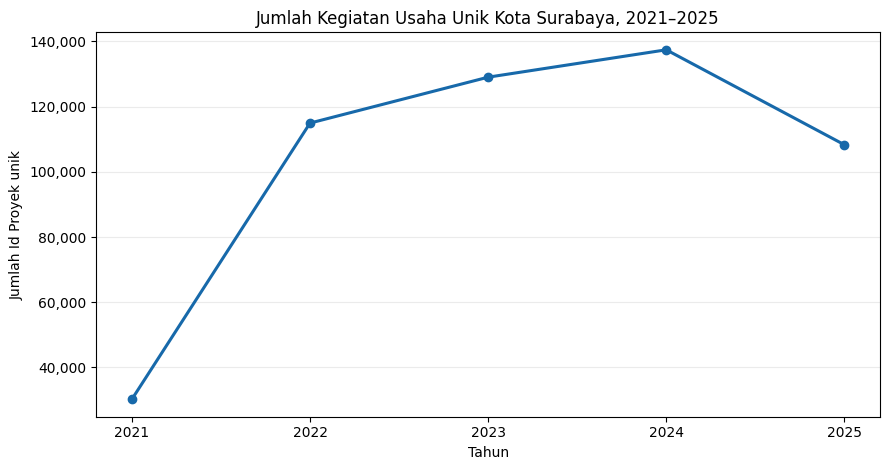

In [4]:
annual_table = annual.rename(columns={
    "jumlah_kegiatan_usaha": "Jumlah kegiatan usaha",
    "pertumbuhan_yoy_jumlah": "Perubahan YoY (jumlah)",
    "pertumbuhan_yoy_persen": "Perubahan YoY (%)",
    "perubahan_dari_2021_jumlah": "Perubahan dari 2021 (jumlah)",
    "perubahan_dari_2021_persen": "Perubahan dari 2021 (%)",
})
display(
    annual_table.style.format(
        {
            "Jumlah kegiatan usaha": "{:,.0f}",
            "Perubahan YoY (jumlah)": "{:+,.0f}",
            "Perubahan YoY (%)": "{:+.2f}%",
            "Perubahan dari 2021 (jumlah)": "{:+,.0f}",
            "Perubahan dari 2021 (%)": "{:+.2f}%",
        },
        na_rep="—",
    )
)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(annual["Tahun"], annual["jumlah_kegiatan_usaha"], marker="o", linewidth=2.2, color="#1769aa")
ax.set(title="Jumlah Kegiatan Usaha Unik Kota Surabaya, 2021–2025", xlabel="Tahun", ylabel="Jumlah Id Proyek unik")
ax.set_xticks(years)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


**Interpretasi.** Jumlah kegiatan unik meningkat dari 30.252 (2021) menjadi 137.449 (2024), lalu turun menjadi 108.324 (2025). YoY 2025 sebesar −21,19%, sementara jumlah 2025 masih 258,07% di atas 2021. Angka ini menggambarkan jumlah proyek yang tercatat, bukan nilai investasi maupun alasan perubahan.


## 4. Pertumbuhan berdasarkan KBLI

Ringkasan berikut membandingkan pertumbuhan persentase 2021–2025 berdasarkan hasil tersimpan. Jumlah awal dan perubahan absolut disertakan agar laju tinggi pada basis kecil tidak dibaca secara terpisah.


,KBLI 2 digit,KBLI representatif,2021,2025,Perubahan jumlah,Pertumbuhan (%)
75,87,Aktivitas Panti Asuhan Swasta,6,0,-6,-100.00%
76,88,Aktivitas Sosial Swasta Tanpa Akomodasi Lainnya YTDL,6,0,-6,-100.00%
36,39,Aktivitas Remediasi dan Pengelolaan Limbah dan Sampah Lainnya,7,0,-7,-100.00%
4,06,Pertambangan Minyak Bumi,5,1,-4,-80.00%
19,21,Industri Produk Obat Tradisional untuk Manusia,70,60,-10,-14.29%
49,56,Kedai Makanan,1764,13730,"+11,966",+678.34%
68,78,Penyediaan Sumber Daya Manusia dan Manajemen Fungsi Sumber Daya Manusia,179,1463,"+1,284",+717.32%
77,90,"Aktivitas Hiburan, Seni dan Kreativitas Lainnya",31,271,+240,+774.19%
48,55,Penyediaan Akomodasi Lainnya,216,2251,"+2,035",+942.13%
9,11,Industri Minuman Ringan,190,2453,"+2,263",+1191.05%


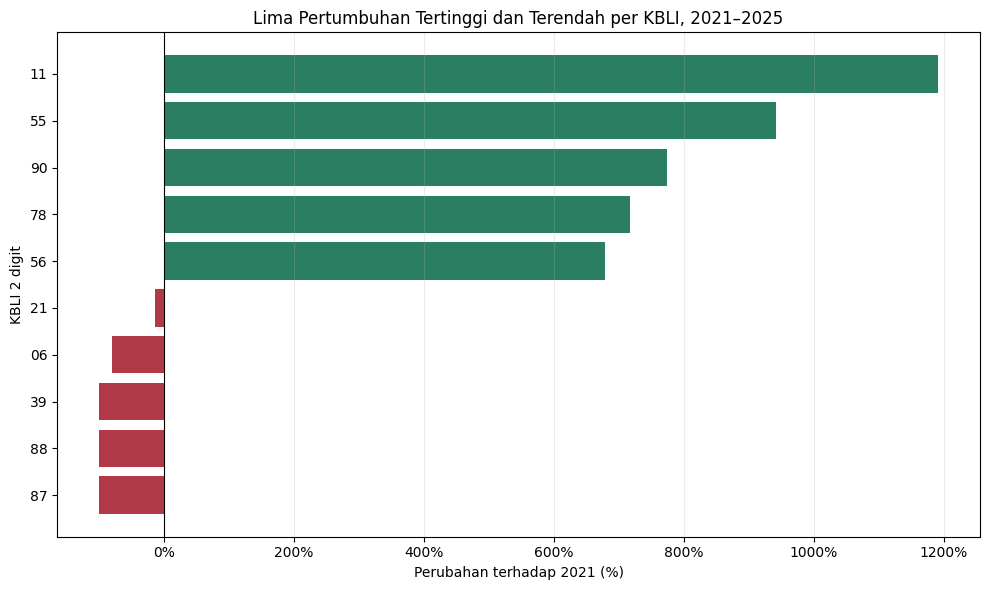

In [5]:
sector_summary = growth_comparison.loc[growth_comparison["jenis_entitas"].eq("KBLI 2 digit")].copy()
sector_summary["nama_entitas"] = sector_summary["nama_entitas"].astype("string").str.zfill(2)
sector_extremes = pd.concat(
    [
        sector_summary.nlargest(5, "pertumbuhan_2021_2025_persen"),
        sector_summary.nsmallest(5, "pertumbuhan_2021_2025_persen"),
    ]
).drop_duplicates("nama_entitas").sort_values("pertumbuhan_2021_2025_persen")
sector_labels = combined.set_index("KBLI_2digit")["Judul_KBLI_5_digit_terbanyak"]
sector_extremes["KBLI representatif"] = sector_extremes["nama_entitas"].map(sector_labels)
display(
    sector_extremes[
        ["nama_entitas", "KBLI representatif", "2021", "2025", "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen"]
    ].rename(
        columns={
            "nama_entitas": "KBLI 2 digit",
            "perubahan_2021_2025_jumlah": "Perubahan jumlah",
            "pertumbuhan_2021_2025_persen": "Pertumbuhan (%)",
        }
    ).style.format(
        {"Perubahan jumlah": "{:+,.0f}", "Pertumbuhan (%)": "{:+.2f}%"},
        na_rep="—",
    )
)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#b23a48" if value < 0 else "#2a7f62" for value in sector_extremes["pertumbuhan_2021_2025_persen"]]
ax.barh(sector_extremes["nama_entitas"], sector_extremes["pertumbuhan_2021_2025_persen"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Lima Pertumbuhan Tertinggi dan Terendah per KBLI, 2021–2025", xlabel="Perubahan terhadap 2021 (%)", ylabel="KBLI 2 digit")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0f}%"))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


### Grafik tren jumlah kegiatan menurut KBLI

Untuk menjaga keterbacaan, grafik menampilkan sepuluh KBLI dengan jumlah kegiatan terbesar pada 2025. Nilai tiap tahun tetap memakai hitungan `Id Proyek` unik per KBLI-tahun. Sumber: dataset hasil cleaning `data_clean.csv`, diolah.


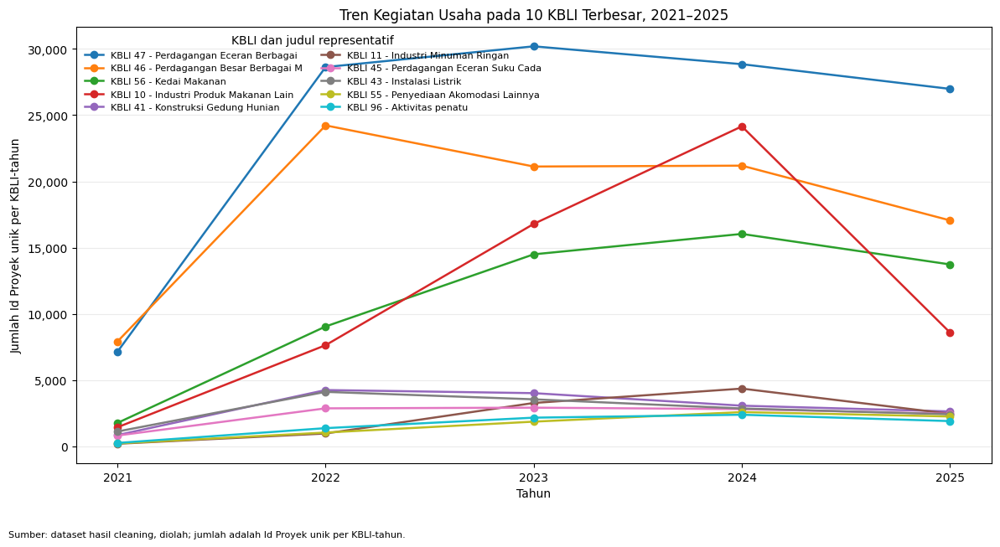

In [6]:
sector_codes_plot = sector_year_counts[2025].nlargest(10).index.tolist()
sector_labels = sector_distribution.set_index("KBLI_2digit")["Judul_KBLI_5_digit_terbanyak"]

fig, ax = plt.subplots(figsize=(12, 6.5))
for code in sector_codes_plot:
    title = str(sector_labels.get(code, "Judul KBLI tidak tersedia"))
    ax.plot(
        years,
        sector_year_counts.loc[code, years].to_numpy(),
        marker="o",
        linewidth=1.8,
        label=f"KBLI {code} - {title[:28]}",
    )
ax.set(
    title="Tren Kegiatan Usaha pada 10 KBLI Terbesar, 2021–2025",
    xlabel="Tahun",
    ylabel="Jumlah Id Proyek unik per KBLI-tahun",
)
ax.set_xticks(years)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.legend(title="KBLI dan judul representatif", ncol=2, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.text(0.01, 0.005, "Sumber: dataset hasil cleaning, diolah; jumlah adalah Id Proyek unik per KBLI-tahun.", fontsize=8)
plt.show()


**Interpretasi.** KBLI 11 memiliki CAGR persentase tertinggi (+1.191,05%), dari 190 menjadi 2.453 kegiatan; nilai tersebut peka terhadap basis 2021 yang kecil. Pada grafik sepuluh KBLI terbesar 2025, KBLI 47 tetap menjadi kelompok terbesar sepanjang periode, sedangkan KBLI 10 naik hingga 2024 lalu menurun pada 2025. Perubahan volume dan CAGR persentase menjawab pertanyaan berbeda dan perlu dibaca bersama.


## 5. Pertumbuhan berdasarkan kecamatan

Tabel mencakup seluruh kecamatan dan memperlihatkan jumlah kegiatan pada kedua endpoint, perubahan absolut, serta persentase pertumbuhan kumulatif.


,Kecamatan,2021,2025,Perubahan jumlah,Pertumbuhan (%)
103,Semampir,371,3075,"+2,704",+728.84%
94,Kenjeran,635,4254,"+3,619",+569.92%
86,Bulak,237,1374,"+1,137",+479.75%
109,Tegalsari,712,3453,"+2,741",+384.97%
104,Simokerto,409,1810,"+1,401",+342.54%
102,Sawahan,1028,4507,"+3,479",+338.42%
84,Benowo,626,2734,"+2,108",+336.74%
112,Wonocolo,981,4283,"+3,302",+336.60%
87,Dukuh Pakis,1015,4223,"+3,208",+316.06%
93,Karang Pilang,668,2770,"+2,102",+314.67%


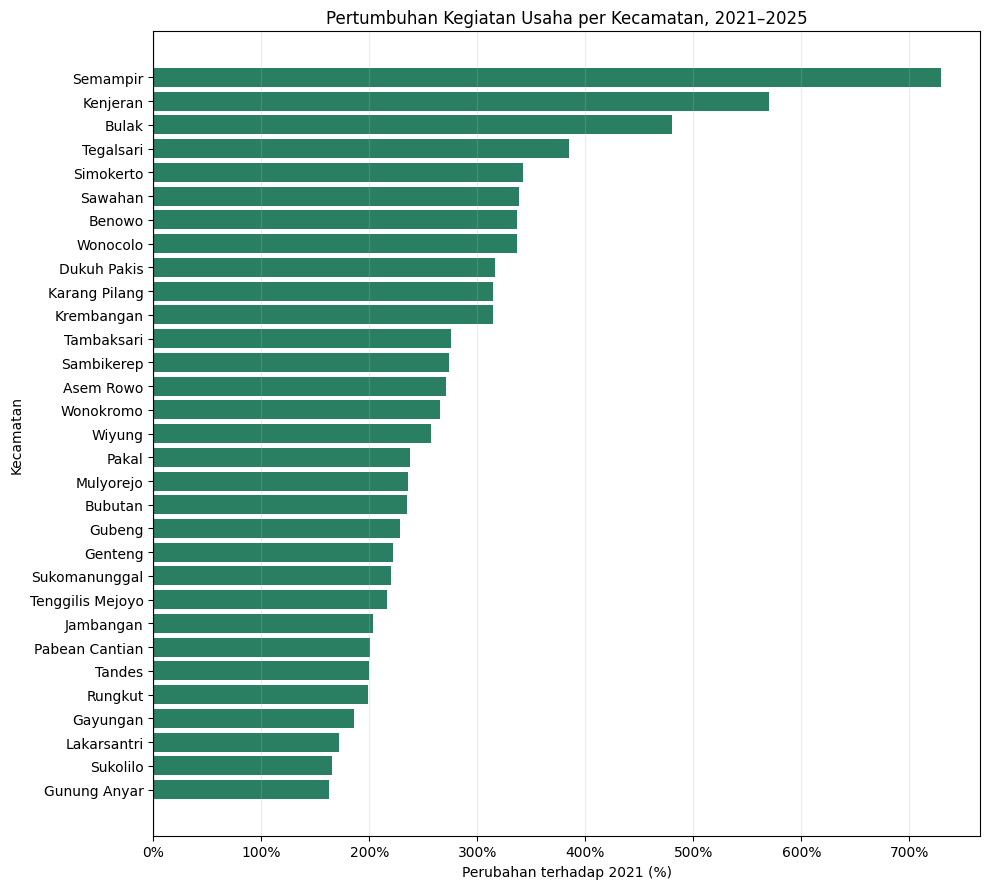

In [7]:
district_summary = growth_comparison.loc[growth_comparison["jenis_entitas"].eq("Kecamatan")].copy()
district_summary = district_summary.sort_values("pertumbuhan_2021_2025_persen", ascending=False)
display(
    district_summary[
        ["nama_entitas", "2021", "2025", "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen"]
    ].rename(
        columns={
            "nama_entitas": "Kecamatan",
            "perubahan_2021_2025_jumlah": "Perubahan jumlah",
            "pertumbuhan_2021_2025_persen": "Pertumbuhan (%)",
        }
    ).style.format({"Perubahan jumlah": "{:+,.0f}", "Pertumbuhan (%)": "{:+.2f}%"})
)

district_plot = district_summary.sort_values("pertumbuhan_2021_2025_persen")
fig, ax = plt.subplots(figsize=(10, 9))
colors = ["#b23a48" if value < 0 else "#2a7f62" for value in district_plot["pertumbuhan_2021_2025_persen"]]
ax.barh(district_plot["nama_entitas"], district_plot["pertumbuhan_2021_2025_persen"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Pertumbuhan Kegiatan Usaha per Kecamatan, 2021–2025", xlabel="Perubahan terhadap 2021 (%)", ylabel="Kecamatan")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0f}%"))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


**Interpretasi.** Semampir mencatat pertumbuhan kumulatif tertinggi (+728,84%; +2.704 kegiatan), sedangkan Gunung Anyar terendah (+162,57%; +1.733 kegiatan). Semua kecamatan tetap bertambah pada endpoint 2021–2025, walaupun beberapa mengalami penurunan YoY pada tahun-tahun terakhir.


## 6. Analisis Location Quotient (LQ)

Kategori LQ di bawah adalah hitungan kombinasi kecamatan–KBLI per tahun dari berkas hasil yang tersedia. Jumlah kombinasi dapat berubah antar-tahun karena cakupan observasi; karena itu perubahan hitungan kategori tidak otomatis berarti jumlah kegiatan absolut ikut berubah dengan proporsi sama.


In [8]:
lq_pairs = lq.groupby(["KBLI_2digit", "kecamatan_usaha"], as_index=False).agg(
    tahun_lq_tersedia=("Tahun", "nunique"),
    tahun_basis=("Kategori_LQ", lambda values: values.eq("Basis (Konsentrasi Tinggi)").sum()),
    rata_rata_lq=("LQ", "mean"),
)
activity_2025 = (
    lq.loc[lq["Tahun"].eq(2025), ["KBLI_2digit", "kecamatan_usaha", "jumlah_kegiatan_usaha"]]
    .rename(columns={"jumlah_kegiatan_usaha": "jumlah_kegiatan_2025"})
)
lq_pairs = lq_pairs.merge(
    activity_2025,
    on=["KBLI_2digit", "kecamatan_usaha"],
    how="left",
    validate="one_to_one",
)

# Editorial shortlist only: complete five-year LQ, basis in all years, and at least 20 activities in 2025.
selected_pairs = (
    lq_pairs.loc[
        lq_pairs["tahun_lq_tersedia"].eq(5)
        & lq_pairs["tahun_basis"].eq(5)
        & lq_pairs["jumlah_kegiatan_2025"].ge(20)
    ]
    .nlargest(5, "rata_rata_lq")
    .copy()
)
if len(selected_pairs) != 5:
    raise ValueError(f"Diharapkan lima pasangan representatif, ditemukan {len(selected_pairs)}.")

selected_lq = lq.merge(
    selected_pairs[["KBLI_2digit", "kecamatan_usaha", "rata_rata_lq", "jumlah_kegiatan_2025"]],
    on=["KBLI_2digit", "kecamatan_usaha"],
    how="inner",
    validate="many_to_one",
).sort_values(["rata_rata_lq", "KBLI_2digit", "kecamatan_usaha", "Tahun"], ascending=[False, True, True, True])
selected_table = selected_lq[[
    "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak", "kecamatan_usaha", "Tahun",
    "jumlah_kegiatan_usaha", "LQ", "Kategori_LQ",
]].rename(columns={
    "KBLI_2digit": "KBLI 2 digit",
    "Judul_KBLI_5_digit_terbanyak": "Judul KBLI representatif",
    "kecamatan_usaha": "Kecamatan",
    "Tahun": "Tahun",
    "jumlah_kegiatan_usaha": "Jumlah kegiatan",
    "LQ": "Nilai LQ",
    "Kategori_LQ": "Klasifikasi",
})
display(
    selected_table.style
    .set_properties(
        subset=["Judul KBLI representatif"],
        **{"white-space": "normal", "max-width": "360px"},
    )
    .format({"Jumlah kegiatan": "{:,.0f}", "Nilai LQ": "{:.4f}"})
)

selected_pair_summary = selected_pairs[[
    "KBLI_2digit", "kecamatan_usaha", "rata_rata_lq", "jumlah_kegiatan_2025"
]].merge(
    sector_distribution[["KBLI_2digit", "Judul_KBLI_5_digit_terbanyak"]],
    on="KBLI_2digit",
    how="left",
    validate="many_to_one",
)
display(
    selected_pair_summary[[
        "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak", "kecamatan_usaha",
        "rata_rata_lq", "jumlah_kegiatan_2025",
    ]].rename(columns={
        "KBLI_2digit": "KBLI 2 digit",
        "Judul_KBLI_5_digit_terbanyak": "Judul KBLI representatif",
        "kecamatan_usaha": "Kecamatan",
        "rata_rata_lq": "Rata-rata LQ 2021–2025",
        "jumlah_kegiatan_2025": "Jumlah kegiatan 2025",
    }).style.format({
        "Rata-rata LQ 2021–2025": "{:.4f}",
        "Jumlah kegiatan 2025": "{:,.0f}",
    })
)


,KBLI 2 digit,Judul KBLI representatif,Kecamatan,Tahun,Jumlah kegiatan,Nilai LQ,Klasifikasi
15,50,Angkutan Laut Dalam Negeri untuk Barang Umum,Pabean Cantian,2021,7,5.5009,Basis (Konsentrasi Tinggi)
16,50,Angkutan Laut Dalam Negeri untuk Barang Umum,Pabean Cantian,2022,34,4.9250,Basis (Konsentrasi Tinggi)
17,50,Angkutan Laut Dalam Negeri untuk Barang Umum,Pabean Cantian,2023,51,10.4009,Basis (Konsentrasi Tinggi)
18,50,Angkutan Laut Dalam Negeri untuk Barang Umum,Pabean Cantian,2024,37,8.6844,Basis (Konsentrasi Tinggi)
19,50,Angkutan Laut Dalam Negeri untuk Barang Umum,Pabean Cantian,2025,47,8.3866,Basis (Konsentrasi Tinggi)
0,52,Pergudangan dan Penyimpanan,Asem Rowo,2021,53,5.0173,Basis (Konsentrasi Tinggi)
1,52,Pergudangan dan Penyimpanan,Asem Rowo,2022,218,5.3245,Basis (Konsentrasi Tinggi)
2,52,Pergudangan dan Penyimpanan,Asem Rowo,2023,164,7.3256,Basis (Konsentrasi Tinggi)
3,52,Pergudangan dan Penyimpanan,Asem Rowo,2024,174,7.5849,Basis (Konsentrasi Tinggi)
4,52,Pergudangan dan Penyimpanan,Asem Rowo,2025,269,7.5526,Basis (Konsentrasi Tinggi)


,KBLI 2 digit,Judul KBLI representatif,Kecamatan,Rata-rata LQ 2021–2025,Jumlah kegiatan 2025
0,50,Angkutan Laut Dalam Negeri untuk Barang Umum,Pabean Cantian,7.5796,47
1,52,Pergudangan dan Penyimpanan,Asem Rowo,6.5610,269
2,50,Angkutan Laut Dalam Negeri untuk Barang Umum,Krembangan,5.8731,35
3,52,Pergudangan dan Penyimpanan,Pabean Cantian,3.8166,92
4,52,Pergudangan dan Penyimpanan,Krembangan,3.5088,95


**Interpretasi.** Pasangan kecamatan–KBLI pada tabel dipilih dari kombinasi dengan LQ tersedia dan berstatus basis pada seluruh lima tahun serta sedikitnya 20 kegiatan pada 2025; lima pasangan dengan rata-rata LQ tertinggi dari shortlist tersebut ditampilkan. Filter jumlah kegiatan membantu menghindari pemilihan LQ ekstrem yang bertumpu pada satu atau dua kegiatan. Kriteria ini hanya untuk tabel representatif dan tidak mengubah nilai maupun klasifikasi LQ. KBLI 50 di Pabean Cantian dan KBLI 52 di Asem Rowo merupakan contoh konsentrasi yang konsisten dengan dukungan jumlah kegiatan lebih besar.


## 7. Analisis sektor dan wilayah basis/non-basis

Grafik membandingkan **jumlah kombinasi kecamatan–KBLI** dengan LQ basis dan non-basis per tahun, bukan menjumlahkan nilai LQ. Tabel juga menyajikan jumlah kombinasi setara, total kombinasi terklasifikasi, dan proporsi kombinasi basis.


Kategori_LQ,Kombinasi basis,Kombinasi non-basis,Kombinasi setara,Jumlah kombinasi terklasifikasi,Proporsi basis (%)
Tahun,,,,,
2021,916,822,0,"1,738",52.7%
2022,"1,007","1,160",0,"2,167",46.5%
2023,962,"1,164",0,"2,126",45.2%
2024,"1,031","1,100",0,"2,131",48.4%
2025,968,"1,148",2,"2,118",45.7%


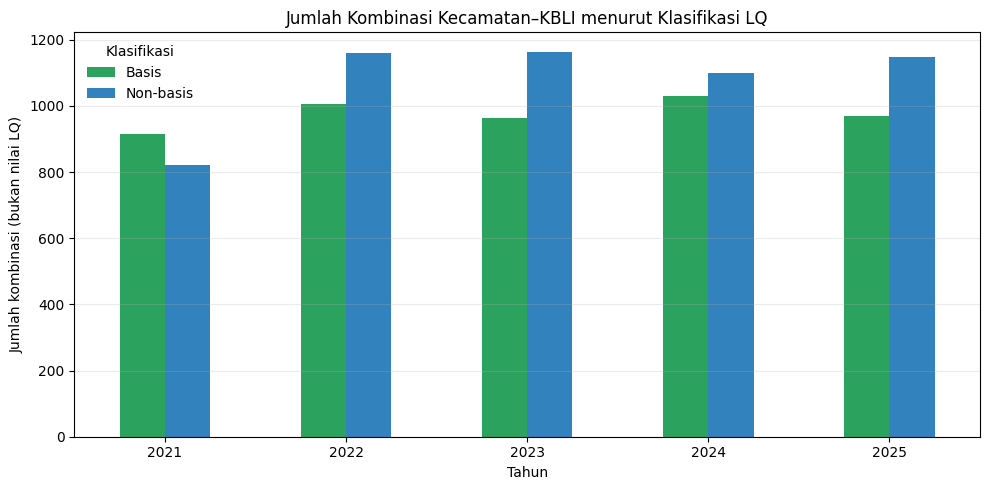

In [9]:
basis_category = "Basis (Konsentrasi Tinggi)"
nonbasis_category = "Non-Basis (Konsentrasi Rendah)"
equal_category = "Setara dengan Kota"
basis_counts = lq_categories.pivot_table(
    index="Tahun",
    columns="Kategori_LQ",
    values="jumlah_kombinasi_kecamatan_sektor",
    aggfunc="sum",
    fill_value=0,
).reindex(years, fill_value=0)
for category in (basis_category, nonbasis_category, equal_category):
    if category not in basis_counts.columns:
        basis_counts[category] = 0
basis_counts["Jumlah kombinasi terklasifikasi"] = basis_counts[
    [basis_category, nonbasis_category, equal_category]
].sum(axis=1)
basis_counts["Proporsi basis (%)"] = (
    basis_counts[basis_category] / basis_counts["Jumlah kombinasi terklasifikasi"] * 100
)
display(
    basis_counts.rename(columns={
        basis_category: "Kombinasi basis",
        nonbasis_category: "Kombinasi non-basis",
        equal_category: "Kombinasi setara",
    }).style.format({
        "Kombinasi basis": "{:,.0f}",
        "Kombinasi non-basis": "{:,.0f}",
        "Kombinasi setara": "{:,.0f}",
        "Jumlah kombinasi terklasifikasi": "{:,.0f}",
        "Proporsi basis (%)": "{:.1f}%",
    })
)

basis_chart = basis_counts[[basis_category, nonbasis_category]].rename(columns={
    basis_category: "Basis",
    nonbasis_category: "Non-basis",
})
ax = basis_chart.plot(
    kind="bar",
    figsize=(10, 5),
    color={"Basis": "#2ca25f", "Non-basis": "#3182bd"},
)
ax.set(
    title="Jumlah Kombinasi Kecamatan–KBLI menurut Klasifikasi LQ",
    xlabel="Tahun",
    ylabel="Jumlah kombinasi (bukan nilai LQ)",
)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Klasifikasi", frameon=False)
plt.tight_layout()
plt.show()


**Interpretasi.** Proporsi kombinasi basis turun dari 52,7% (916 kombinasi) pada 2021 menjadi 45,7% (968 kombinasi) pada 2025. Jumlah kombinasi basis justru meningkat, tetapi jumlah kombinasi yang dapat diklasifikasikan dan komposisinya juga berubah. Karena grafik menghitung kombinasi kecamatan–KBLI, batang tidak boleh dibaca sebagai nilai LQ atau jumlah proyek.


## 8. Analisis spasial pertumbuhan dan konsentrasi kegiatan usaha

Kedua peta berikut berasal dari peta Folium yang sudah tersedia, memuat batas seluruh 31 kecamatan, dan menggunakan OpenStreetMap. Gambar PNG mengambil tampilan statis tahun 2025; HTML tetap disediakan untuk memilih tahun dan, pada peta LQ, KBLI.


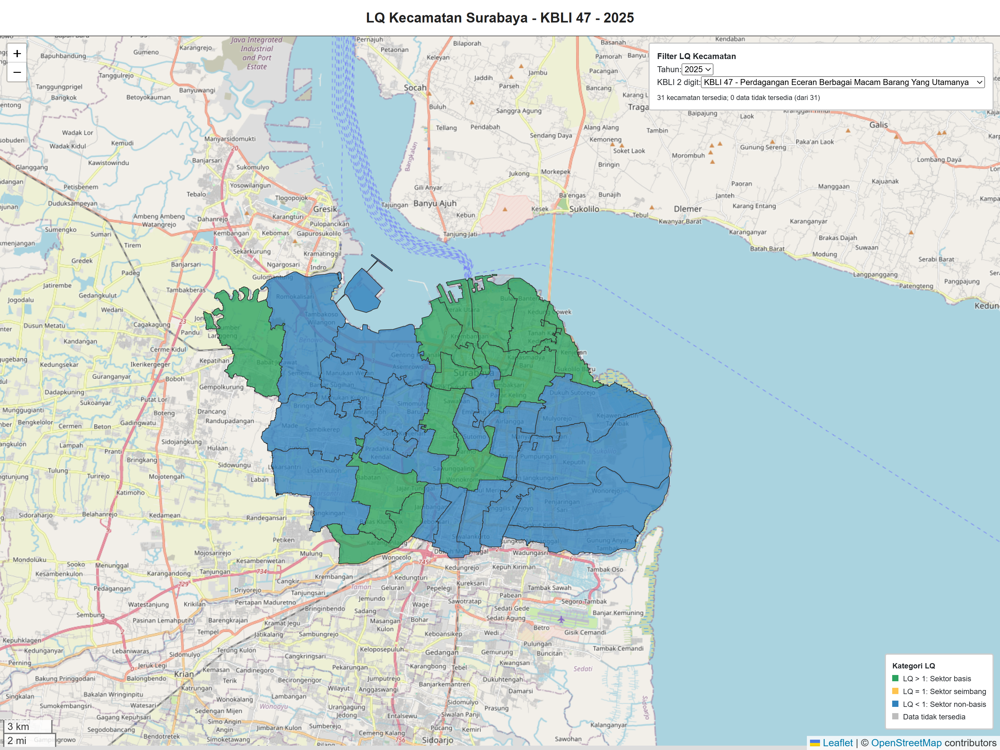

HTML interaktif: D:\DPMPTSP\Project_Akhir\output\peta_choropleth_lq_surabaya.html
PNG publikasi: D:\DPMPTSP\Project_Akhir\output\visualisasi\peta_lq_kbli47_2025.png (3200 × 2400 piksel; KBLI 47, 2025)


In [10]:
lq_map_path = output_dir / "peta_choropleth_lq_surabaya.html"
lq_png_path = output_dir / "visualisasi" / "peta_lq_kbli47_2025.png"
if not lq_png_path.is_file():
    raise FileNotFoundError(f"PNG peta LQ belum tersedia: {lq_png_path}")
with PillowImage.open(lq_png_path) as image:
    if image.format != "PNG" or image.size != (3200, 2400):
        raise ValueError(f"Resolusi PNG peta LQ tidak sesuai: {image.format}, {image.size}")
display(IFrame(src=f"../output/{lq_map_path.name}", width="100%", height=650))
display(Image(filename=str(lq_png_path), alt="Peta LQ kecamatan Surabaya untuk KBLI 47 tahun 2025"))
print(f"HTML interaktif: {lq_map_path}")
print(f"PNG publikasi: {lq_png_path} (3200 × 2400 piksel; KBLI 47, 2025)")


### Peta pertumbuhan YoY kecamatan

Peta HTML menyediakan filter tahun 2022–2025. PNG menampilkan tahun 2025 dan mempertahankan skala warna simetris yang sama dengan peta interaktif; perbedaan nilai 2025 yang relatif dekat nol akan tampak lebih pucat dibanding variasi ekstrem tahun lain.


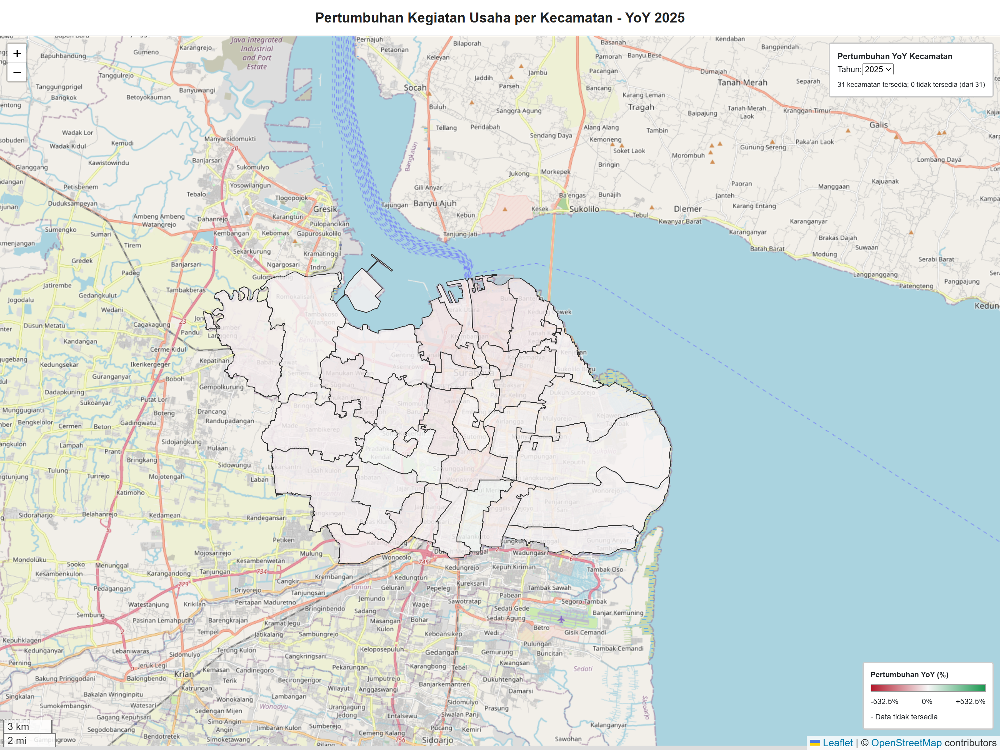

HTML interaktif: D:\DPMPTSP\Project_Akhir\output\peta_choropleth_pertumbuhan_kecamatan.html
PNG publikasi: D:\DPMPTSP\Project_Akhir\output\visualisasi\peta_pertumbuhan_yoy_2025.png (3200 × 2400 piksel; YoY 2025)


In [11]:
growth_map_path = output_dir / "peta_choropleth_pertumbuhan_kecamatan.html"
growth_png_path = output_dir / "visualisasi" / "peta_pertumbuhan_yoy_2025.png"
if not growth_png_path.is_file():
    raise FileNotFoundError(f"PNG peta pertumbuhan belum tersedia: {growth_png_path}")
with PillowImage.open(growth_png_path) as image:
    if image.format != "PNG" or image.size != (3200, 2400):
        raise ValueError(f"Resolusi PNG peta pertumbuhan tidak sesuai: {image.format}, {image.size}")
display(IFrame(src=f"../output/{growth_map_path.name}", width="100%", height=650))
display(Image(filename=str(growth_png_path), alt="Peta pertumbuhan YoY kecamatan Surabaya tahun 2025"))
print(f"HTML interaktif: {growth_map_path}")
print(f"PNG publikasi: {growth_png_path} (3200 × 2400 piksel; YoY 2025)")


## 9. Analisis kombinasi LQ dan CAGR

Klasifikasi menggunakan indikator dan cakupan data yang sama seperti hasil analisis terdahulu; tabel kategori tidak menghitung ulang LQ maupun CAGR.


,Kategori gabungan,Jumlah sektor
0,Sektor Basis dan Tumbuh,58
1,Sektor Basis tetapi Tidak Tumbuh,4
2,Sektor Non-Basis tetapi Tumbuh,18
3,Sektor Non-Basis dan Tidak Tumbuh,0
4,Data tidak memadai,3


Lima sektor basis dan tumbuh dengan CAGR tertinggi


,KBLI 2 digit,Judul KBLI representatif,Jumlah 2021,Jumlah 2025,Rata-rata LQ,CAGR (%)
9,11,Industri Minuman Ringan,190,"2,453",1.0124,+89.56%
77,90,"Aktivitas Hiburan, Seni dan Kreativitas Lainnya",31,271,1.2318,+71.95%
68,78,Penyediaan Sumber Daya Manusia dan Manajemen Fungsi Sumber Daya Manusia,179,"1,463",1.0040,+69.08%
67,77,"Aktivitas Penyewaan dan Sewa Guna Usaha Tanpa Hak Opsi Mobil, Bus, Truk Dan Sejenisnya",232,"1,555",1.0042,+60.90%
45,51,Angkutan Udara Niaga Berjadwal Dalam Negeri untuk Kargo,2,13,8.0941,+59.67%


Sektor basis tetapi tidak tumbuh/menurun


,KBLI 2 digit,Judul KBLI representatif,Jumlah 2021,Jumlah 2025,Rata-rata LQ,CAGR (%)
4,06,Pertambangan Minyak Bumi,5,1,11.5762,-33.13%
19,21,Industri Produk Obat Tradisional untuk Manusia,70,60,1.1657,-3.78%
3,05,Pertambangan Batu Bara,10,9,3.6626,-2.60%
5,07,Pertambangan Bijih Nikel,14,13,3.9846,-1.84%


Lima sektor non-basis tetapi tumbuh dengan CAGR tertinggi


,KBLI 2 digit,Judul KBLI representatif,Jumlah 2021,Jumlah 2025,Rata-rata LQ,CAGR (%)
48,55,Penyediaan Akomodasi Lainnya,216,"2,251",0.9490,+79.67%
49,56,Kedai Makanan,"1,764","13,730",0.9821,+67.03%
81,96,Aktivitas penatu,252,"1,901",0.9914,+65.73%
72,82,Aktivitas Penyedia Gabungan Jasa Administrasi Kantor,269,"1,755",0.9843,+59.82%
73,85,Pendidikan Bimbingan Belajar Dan Konseling Swasta,222,"1,014",0.9993,+46.19%


Sektor dengan data tidak memadai


,KBLI 2 digit,Judul KBLI representatif,Jumlah 2021,Jumlah 2025,Rata-rata LQ,CAGR (%)
36,39,Aktivitas Remediasi dan Pengelolaan Limbah dan Sampah Lainnya,7,0,21.1273,-100.00%
75,87,Aktivitas Panti Asuhan Swasta,6,0,11.7257,-100.00%
76,88,Aktivitas Sosial Swasta Tanpa Akomodasi Lainnya YTDL,6,0,8.5400,-100.00%


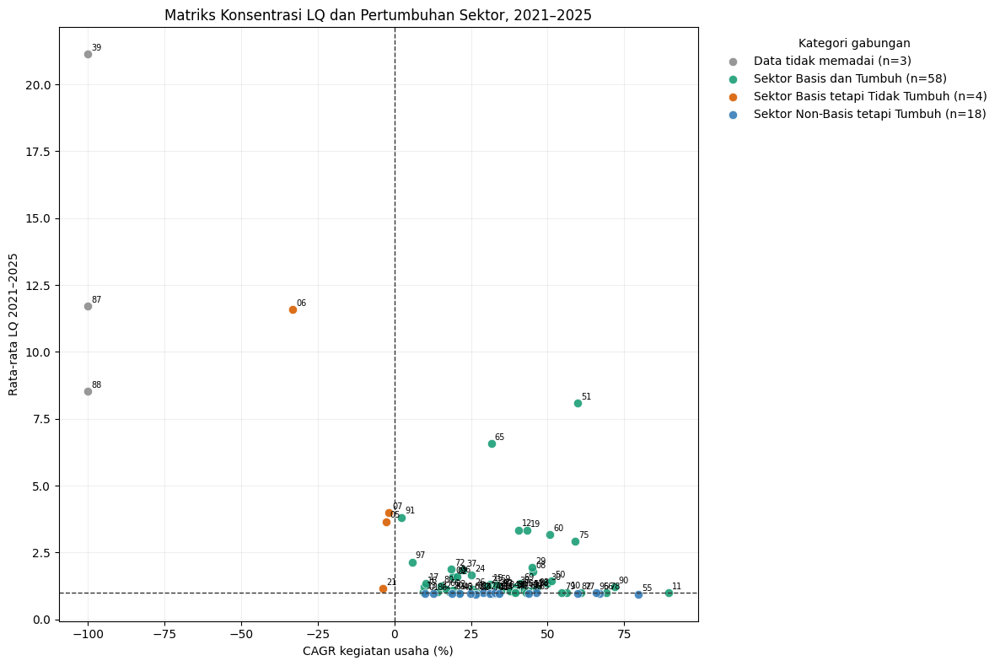

In [12]:
display(combined_categories.rename(columns={
    "kategori_gabungan": "Kategori gabungan",
    "jumlah_sektor": "Jumlah sektor",
}).style.format({"Jumlah sektor": "{:,.0f}"}))

complete = combined.loc[combined["status_data"].eq("Lengkap")].copy()
basis_growing = complete.loc[complete["kategori_gabungan"].eq("Sektor Basis dan Tumbuh")].nlargest(
    5, "cagr_2021_2025_persen"
)
basis_declining = complete.loc[complete["kategori_gabungan"].eq("Sektor Basis tetapi Tidak Tumbuh")].sort_values(
    "cagr_2021_2025_persen"
)
nonbasis_growing = complete.loc[complete["kategori_gabungan"].eq("Sektor Non-Basis tetapi Tumbuh")].nlargest(
    5, "cagr_2021_2025_persen"
)
incomplete = combined.loc[combined["kategori_gabungan"].eq("Data tidak memadai")]

def show_sector_table(frame):
    shown = frame[[
        "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak",
        "jumlah_kegiatan_2021", "jumlah_kegiatan_2025",
        "rata_rata_lq_2021_2025", "cagr_2021_2025_persen",
    ]].rename(columns={
        "KBLI_2digit": "KBLI 2 digit",
        "Judul_KBLI_5_digit_terbanyak": "Judul KBLI representatif",
        "jumlah_kegiatan_2021": "Jumlah 2021",
        "jumlah_kegiatan_2025": "Jumlah 2025",
        "rata_rata_lq_2021_2025": "Rata-rata LQ",
        "cagr_2021_2025_persen": "CAGR (%)",
    })
    display(shown.style.format({
        "Jumlah 2021": "{:,.0f}",
        "Jumlah 2025": "{:,.0f}",
        "Rata-rata LQ": "{:.4f}",
        "CAGR (%)": "{:+.2f}%",
    }))

print("Lima sektor basis dan tumbuh dengan CAGR tertinggi")
show_sector_table(basis_growing)
print("Sektor basis tetapi tidak tumbuh/menurun")
show_sector_table(basis_declining)
print("Lima sektor non-basis tetapi tumbuh dengan CAGR tertinggi")
show_sector_table(nonbasis_growing)
print("Sektor dengan data tidak memadai")
show_sector_table(incomplete)

colors = {
    "Sektor Basis dan Tumbuh": "#1b9e77",
    "Sektor Basis tetapi Tidak Tumbuh": "#d95f02",
    "Sektor Non-Basis tetapi Tumbuh": "#377eb8",
    "Sektor Non-Basis dan Tidak Tumbuh": "#984ea3",
    "Data tidak memadai": "#8c8c8c",
}
fig, ax = plt.subplots(figsize=(12, 8))
for category, frame in combined.groupby("kategori_gabungan"):
    ax.scatter(
        frame["cagr_2021_2025_persen"],
        frame["rata_rata_lq_2021_2025"],
        s=55,
        color=colors[category],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.9,
        label=f"{category} (n={len(frame)})",
    )
for row in combined.itertuples(index=False):
    if pd.notna(row.cagr_2021_2025_persen) and pd.notna(row.rata_rata_lq_2021_2025):
        ax.annotate(
            row.KBLI_2digit,
            (row.cagr_2021_2025_persen, row.rata_rata_lq_2021_2025),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=7,
        )
ax.axvline(0, color="#333333", linestyle="--", linewidth=1)
ax.axhline(1, color="#333333", linestyle="--", linewidth=1)
ax.set(
    title="Matriks Konsentrasi LQ dan Pertumbuhan Sektor, 2021–2025",
    xlabel="CAGR kegiatan usaha (%)",
    ylabel="Rata-rata LQ 2021–2025",
)
ax.grid(alpha=0.2)
ax.legend(title="Kategori gabungan", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.tight_layout()
plt.show()


**Interpretasi.** Sebanyak 58 sektor masuk kategori basis dan tumbuh; 4 basis tetapi tidak tumbuh/menurun; 18 non-basis tetapi tumbuh; dan 3 memiliki data tidak memadai (KBLI 39, 87, 88). KBLI 11 memiliki CAGR tertinggi pada kelompok basis-tumbuh (+89,56%); KBLI 06 mencatat penurunan terdalam di kelompok basis (−33,13%). Klasifikasi gabungan memisahkan sektor yang pertumbuhan atau cakupan LQ-nya tidak memadai.


## 10. Ringkasan hasil analisis, keterbatasan, dan kesimpulan

### Perbedaan agregat 2024

Validasi menemukan jumlah hasil agregasi kecamatan–sektor yang menjadi basis tabel LQ pada 2024 adalah **137.450**, sedangkan jumlah ID proyek unik tingkat kota adalah **137.449**. Pemeriksaan dataset cleaning menemukan ID `R-202008191343433441918` tercatat pada KBLI 46 di dua kecamatan, Gubeng dan Tambaksari, pada tahun tersebut. Karena unit hitung agregat kecamatan–sektor menghitung ID unik di setiap kombinasi, satu ID tersebut masuk ke dua kombinasi. Hasil dan rumus LQ yang sudah ada dipertahankan; perbedaan satu hitungan ini dicatat sebagai isu atribusi lokasi, bukan dikoreksi secara diam-diam.

### Keterbatasan

- LQ mengukur konsentrasi relatif dan dapat tinggi pada jumlah kegiatan yang kecil.
- CAGR hanya memakai endpoint 2021 dan 2025; laju sektor dengan baseline kecil dapat tampak ekstrem.
- Jumlah proyek bukan nilai investasi, output, produktivitas, tenaga kerja, atau ukuran keseluruhan perekonomian.
- Tiga kode KBLI (39, 87, 88) tidak memiliki cakupan LQ lengkap untuk klasifikasi lima tahun.
- Peta bersifat deskriptif; tidak dilakukan uji ketergantungan spasial ataupun analisis penyebab perubahan.
- Judul KBLI representatif yang ditampilkan tidak menggantikan pemetaan ke nama resmi sektor 2 digit.

### Kesimpulan

Hasil 2021–2025 memperlihatkan kelompok basis-tumbuh yang besar, perubahan jumlah kegiatan kota yang turun pada 2025 dibandingkan 2024, serta variasi pertumbuhan antar-kecamatan. Temuan ini dapat menjadi titik awal pendalaman promosi dan fasilitasi investasi, setelah dilengkapi validasi atribusi lokasi, metadata KBLI resmi, dan indikator nilai investasi serta tenaga kerja. Gunakan berkas hasil tersimpan sebagai sumber tabel; jalankan ulang notebook dari atas untuk menampilkan tabel, grafik, dan peta.
